<a href="https://colab.research.google.com/github/I7411/AI-AttendanceSystem/blob/main/20_huynhthanhminhtam_LAB1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bước 0. Thiết lập Colab mới, tải dữ liệu về /content và khởi tạo Spark

In [15]:
import logging
import os

# (Tùy chọn) Ẩn dòng cảnh báo google_auth_httplib2
logging.getLogger("google_auth_httplib2").setLevel(logging.ERROR)

DATA_PATH = "/content/Lab01_Bai2_US_Parcel_Shipments.csv"
size_mib = os.path.getsize(DATA_PATH) / (1024 ** 2)
print(f"Dung lượng tệp hiện tại: {size_mib:.2f} MiB")

# Xem thử 3 dòng đầu để chắc chắn dữ liệu CSV nguyên vẹn
with open(DATA_PATH, "r", encoding="utf-8") as f:
    for _ in range(3):
        print(f.readline().strip())

Dung lượng tệp hiện tại: 36.56 MiB
shipment_id,ship_date,origin_city,origin_state,destination_city,destination_state,customer_segment,service_level,package_type,weight_kg,distance_km,base_fee_usd,fuel_surcharge_usd,insurance_fee_usd,total_shipping_usd,promised_days,delivery_days,on_time,hub_code,label_color,scanner_batch
70000006,2024-04-25,Boston,MA,Denver,CO,Marketplace,Standard,Oversize,18.15,3324,87.76,6.58,4.50,98.84,6,5,1,HUB-S04,White,2001
70000017,2025-01-03,Phoenix,AZ,Seattle,WA,Business,Express,Parcel,17.70,2099,74.33,5.57,1.25,81.15,2,1,1,HUB-N01,White,2001


In [16]:
import gc
import logging
import os
import time
import pandas as pd
import matplotlib.pyplot as plt

try:
    import pyspark
except ImportError:
    !pip install -q pyspark

from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from pyspark.sql import SparkSession, functions as F, types as T

logging.getLogger("google_auth_httplib2").setLevel(logging.ERROR)

# 1. Tải tệp CSV gốc về /content (tự động xóa nếu gặp tệp rỗng 0 byte)
DATA_PATH = "/content/Lab01_Bai2_US_Parcel_Shipments.csv"

if os.path.exists(DATA_PATH) and os.path.getsize(DATA_PATH) == 0:
    os.remove(DATA_PATH)

if not os.path.exists(DATA_PATH):
    auth.authenticate_user()
    drive_service = build("drive", "v3")
    res = drive_service.files().list(
        q="name = 'Lab01_Bai2_US_Parcel_Shipments.csv' and mimeType = 'text/csv' and trashed = false",
        fields="files(id, name, mimeType, size)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True,
        pageSize=5,
    ).execute()
    matched = res.get("files", [])
    assert matched, "Không tìm thấy tệp Lab01_Bai2_US_Parcel_Shipments.csv trên Google Drive!"

    request = drive_service.files().get_media(fileId=matched[0]["id"])
    with open(DATA_PATH, "wb") as f:
        downloader = MediaIoBaseDownload(f, request)
        done = False
        while not done:
            _, done = downloader.next_chunk()

# 2. Khởi tạo SparkSession ở chế độ local[*]
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Lab01_Bai2_Cedarline_Parcel")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

# 3. Kiểm tra cấu hình và nạp thử dữ liệu vào PySpark DataFrame
ram_gib = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / (1024 ** 3)
print(f"Tệp cục bộ sẵn sàng: {DATA_PATH} ({os.path.getsize(DATA_PATH)/(1024**2):.2f} MiB)")
print(f"Số lõi CPU (vCPU): {os.cpu_count()} | Tổng RAM máy ảo: {ram_gib:.2f} GiB")
print(f"PySpark version: {pyspark.__version__}")

df = spark.read.csv(DATA_PATH, header=True, inferSchema=True)
print(f"Tổng số dòng dữ liệu: {df.count():,}")

Tệp cục bộ sẵn sàng: /content/Lab01_Bai2_US_Parcel_Shipments.csv (36.56 MiB)
Số lõi CPU (vCPU): 2 | Tổng RAM máy ảo: 12.67 GiB
PySpark version: 4.0.5
Tổng số dòng dữ liệu: 300,000


Câu 1. Khảo sát CSV và đối chiếu phần giới thiệu

In [17]:
df_full = pd.read_csv(DATA_PATH)

n_rows, n_cols = df_full.shape
size_mib = os.path.getsize(DATA_PATH) / (1024 ** 2)
date_min = df_full["ship_date"].min()
date_max = df_full["ship_date"].max()
n_origin_cities = df_full["origin_city"].nunique()
n_dest_cities = df_full["destination_city"].nunique()

summary_q1 = pd.DataFrame([
    {"Chỉ tiêu khảo sát": "Số bản ghi (dòng)", "Kết quả đo thực tế": f"{n_rows:,}", "Giới thiệu Mục 2.1": "300.000 bản ghi"},
    {"Chỉ tiêu khảo sát": "Số thuộc tính (cột)", "Kết quả đo thực tế": n_cols, "Giới thiệu Mục 2.1": "21 thuộc tính"},
    {"Chỉ tiêu khảo sát": "Dung lượng tệp trên đĩa (MiB)", "Kết quả đo thực tế": f"{size_mib:.2f} MiB", "Giới thiệu Mục 2.1": "Tệp Lab01_Bai2_US_Parcel_Shipments.csv"},
    {"Chỉ tiêu khảo sát": "Ngày gửi đầu tiên (ship_date min)", "Kết quả đo thực tế": date_min, "Giới thiệu Mục 2.1": "Chuỗi thời gian giao nhận nội địa Mỹ"},
    {"Chỉ tiêu khảo sát": "Ngày gửi cuối cùng (ship_date max)", "Kết quả đo thực tế": date_max, "Giới thiệu Mục 2.1": "Chuỗi thời gian giao nhận nội địa Mỹ"},
    {"Chỉ tiêu khảo sát": "Số thành phố xuất phát (origin_city)", "Kết quả đo thực tế": n_origin_cities, "Giới thiệu Mục 2.1": "Nhiều thành phố tại Hoa Kỳ"},
    {"Chỉ tiêu khảo sát": "Số thành phố đích (destination_city)", "Kết quả đo thực tế": n_dest_cities, "Giới thiệu Mục 2.1": "Nhiều thành phố tại Hoa Kỳ"},
])
print(summary_q1.to_string(index=False))

                   Chỉ tiêu khảo sát Kết quả đo thực tế                     Giới thiệu Mục 2.1
                   Số bản ghi (dòng)            300,000                        300.000 bản ghi
                 Số thuộc tính (cột)                 21                          21 thuộc tính
       Dung lượng tệp trên đĩa (MiB)          36.56 MiB Tệp Lab01_Bai2_US_Parcel_Shipments.csv
   Ngày gửi đầu tiên (ship_date min)         2024-01-01   Chuỗi thời gian giao nhận nội địa Mỹ
  Ngày gửi cuối cùng (ship_date max)         2025-12-31   Chuỗi thời gian giao nhận nội địa Mỹ
Số thành phố xuất phát (origin_city)                 12             Nhiều thành phố tại Hoa Kỳ
Số thành phố đích (destination_city)                 12             Nhiều thành phố tại Hoa Kỳ


Câu 2. Tạo 4 mức dữ liệu gốc và mức mở rộng 900.000 dòng

In [18]:
SUBSET_DIR = "/content/bai2_subsets"
os.makedirs(SUBSET_DIR, exist_ok=True)

BASE_SIZES = [50_000, 100_000, 200_000, 300_000]
FILES = {}
subset_report = []

# 1. Tạo 4 mức dữ liệu gốc (50k, 100k, 200k, 300k)
for n in BASE_SIZES:
    out_path = f"{SUBSET_DIR}/shipments_{n}.csv"
    sub = df_full.iloc[:n]
    sub.to_csv(out_path, index=False)
    FILES[n] = out_path
    subset_report.append({
        "Mức dữ liệu": f"{n:,}",
        "Số dòng": len(sub),
        "Số cột": sub.shape[1],
        "Số shipment_id duy nhất": sub["shipment_id"].nunique(),
        "Dung lượng (MiB)": round(os.path.getsize(out_path) / (1024 ** 2), 2),
        "Ghi chú": "Dữ liệu gốc",
    })

# 2. Tạo mức mở rộng 900.000 dòng (duy trì 21 cột, không trùng shipment_id)
part1 = df_full.copy()
part2 = df_full.copy()
part3 = df_full.copy()

# Dịch chuyển shipment_id để bảo đảm 900.000 mã vận đơn là duy nhất tuyệt đối
id_step = 10_000_000
part2["shipment_id"] = part2["shipment_id"] + id_step
part3["shipment_id"] = part3["shipment_id"] + 2 * id_step

df_900k = pd.concat([part1, part2, part3], ignore_index=True)
assert df_900k.shape == (900_000, 21), "Sai kích thước tập 900k!"
assert df_900k["shipment_id"].nunique() == 900_000, "Bị trùng shipment_id!"

path_900k = f"{SUBSET_DIR}/shipments_900000_SYNTHETIC_BENCHMARK_ONLY.csv"
df_900k.to_csv(path_900k, index=False)
FILES[900_000] = path_900k
SIZES = BASE_SIZES + [900_000]

subset_report.append({
    "Mức dữ liệu": "900,000",
    "Số dòng": len(df_900k),
    "Số cột": df_900k.shape[1],
    "Số shipment_id duy nhất": df_900k["shipment_id"].nunique(),
    "Dung lượng (MiB)": round(os.path.getsize(path_900k) / (1024 ** 2), 2),
    "Ghi chú": "[DỮ LIỆU MỞ RỘNG - CHỈ PHỤC VỤ ĐO HIỆU NĂNG]",
})

# Giải phóng biến lớn khỏi RAM trước khi đo benchmark
del df_full, part1, part2, part3, df_900k
gc.collect()

print(pd.DataFrame(subset_report).to_string(index=False))

Mức dữ liệu  Số dòng  Số cột  Số shipment_id duy nhất  Dung lượng (MiB)                                      Ghi chú
     50,000    50000      21                    50000              6.02                                  Dữ liệu gốc
    100,000   100000      21                   100000             12.05                                  Dữ liệu gốc
    200,000   200000      21                   200000             24.09                                  Dữ liệu gốc
    300,000   300000      21                   300000             36.13                                  Dữ liệu gốc
    900,000   900000      21                   900000            108.40 [DỮ LIỆU MỞ RỘNG - CHỈ PHỤC VỤ ĐO HIỆU NĂNG]


Câu 3. Thực hiện nghiệp vụ bằng Pandas và PySpark, đối chiếu kết quả

In [19]:
# Chỉ chọn 5 cột tham gia nghiệp vụ cho Pandas để tránh đọc 16 cột dư thừa
CORE_COLS = [
    "origin_state",
    "service_level",
    "weight_kg",
    "distance_km",
    "total_shipping_usd",
]

# Khai báo tường minh schema 21 cột cho PySpark để tránh chi phí inferSchema
SHIPMENT_SCHEMA = T.StructType([
    T.StructField("shipment_id", T.LongType()),
    T.StructField("ship_date", T.StringType()),
    T.StructField("origin_city", T.StringType()),
    T.StructField("origin_state", T.StringType()),
    T.StructField("destination_city", T.StringType()),
    T.StructField("destination_state", T.StringType()),
    T.StructField("customer_segment", T.StringType()),
    T.StructField("service_level", T.StringType()),
    T.StructField("package_type", T.StringType()),
    T.StructField("weight_kg", T.DoubleType()),
    T.StructField("distance_km", T.DoubleType()),
    T.StructField("base_fee_usd", T.DoubleType()),
    T.StructField("fuel_surcharge_usd", T.DoubleType()),
    T.StructField("insurance_fee_usd", T.DoubleType()),
    T.StructField("total_shipping_usd", T.DoubleType()),
    T.StructField("promised_days", T.IntegerType()),
    T.StructField("delivery_days", T.IntegerType()),
    T.StructField("on_time", T.IntegerType()),
    T.StructField("hub_code", T.StringType()),
    T.StructField("label_color", T.StringType()),
    T.StructField("scanner_batch", T.StringType()),
])

def run_pandas_job(path):
    gc.collect()
    start = time.perf_counter()
    df = pd.read_csv(path, usecols=CORE_COLS)
    mem_mib = df.memory_usage(deep=True).sum() / (1024 ** 2)

    filtered = df.loc[
        (df["service_level"] == "Express")
        & (df["weight_kg"] >= 5)
        & (df["distance_km"] >= 500)
    ]
    res = (
        filtered.groupby("origin_state", as_index=False)
        .agg(
            shipments=("origin_state", "count"),
            total_weight_kg=("weight_kg", "sum"),
            total_shipping_usd=("total_shipping_usd", "sum"),
        )
        .sort_values("origin_state")
        .reset_index(drop=True)
    )
    elapsed = time.perf_counter() - start
    return res, elapsed, mem_mib

def run_spark_job(path):
    start = time.perf_counter()
    frame = (
        spark.read.schema(SHIPMENT_SCHEMA)
        .option("header", "true")
        .csv(path)
    )
    res_df = (
        frame.filter(
            (F.col("service_level") == "Express")
            & (F.col("weight_kg") >= 5)
            & (F.col("distance_km") >= 500)
        )
        .groupBy("origin_state")
        .agg(
            F.count("*").alias("shipments"),
            F.sum("weight_kg").alias("total_weight_kg"),
            F.sum("total_shipping_usd").alias("total_shipping_usd"),
        )
        .orderBy("origin_state")
    )
    rows = res_df.collect()  # Action kích hoạt tính toán và thu kết quả nhỏ
    elapsed = time.perf_counter() - start
    return pd.DataFrame([r.asDict() for r in rows]), elapsed

# Chạy thử trên tập 300.000 dòng và đối chiếu kết quả hai công cụ
pd_300k, pd_t, pd_mem = run_pandas_job(FILES[300_000])
sp_300k, sp_t = run_spark_job(FILES[300_000])

print("=== KẾT QUẢ PANDAS (300.000 DÒNG) ===")
print(pd_300k.to_string(index=False))
print(f"\n=== KẾT QUẢ PYSPARK (300.000 DÒNG) ===")
print(sp_300k.to_string(index=False))

# Kiểm tra khớp 100% giữa hai công cụ
assert list(pd_300k["origin_state"]) == list(sp_300k["origin_state"]), "Lệch danh sách bang!"
assert list(pd_300k["shipments"]) == list(sp_300k["shipments"]), "Lệch số vận đơn!"
assert abs(pd_300k["total_weight_kg"].sum() - sp_300k["total_weight_kg"].sum()) < 1e-3, "Lệch tổng trọng lượng!"
assert abs(pd_300k["total_shipping_usd"].sum() - sp_300k["total_shipping_usd"].sum()) < 1e-2, "Lệch tổng phí!"
print("\n[ĐỐI CHIẾU THÀNH CÔNG]: Kết quả của Pandas và PySpark khớp hoàn toàn!")

=== KẾT QUẢ PANDAS (300.000 DÒNG) ===
origin_state  shipments  total_weight_kg  total_shipping_usd
          AZ       6112         72302.20           468822.51
          CA      11215        133700.70           983529.94
          CO       6277         74624.15           463276.56
          IL       6127         72815.45           466528.22
          MA       5534         66072.95           540604.65
          NY       5275         62955.65           526878.44
          PA       5549         66169.00           513285.93
          TX      14795        177041.55          1231299.43
          WA       6170         73595.35           614428.81

=== KẾT QUẢ PYSPARK (300.000 DÒNG) ===
origin_state  shipments  total_weight_kg  total_shipping_usd
          AZ       6112         72302.20           468822.51
          CA      11215        133700.70           983529.94
          CO       6277         74624.15           463276.56
          IL       6127         72815.45           466528.22
       

Câu 4. Đo thời gian thực hiện trên 5 mức dữ liệu và giải thích điều kiện công bằng

In [20]:
# Chạy khởi động nhẹ (warm-up) để tránh độ trễ nạp lớp JVM ở lần đầu tiên
_ = run_pandas_job(FILES[50_000])
_ = run_spark_job(FILES[50_000])

N_RUNS = 3  # Đo 3 lần mỗi mức để lấy trung vị giảm nhiễu hệ thống
BENCHMARK_RECORDS = []

for n in SIZES:
    for run_id in range(1, N_RUNS + 1):
        p_res, p_sec, p_mib = run_pandas_job(FILES[n])
        s_res, s_sec = run_spark_job(FILES[n])
        assert p_res["shipments"].sum() == s_res["shipments"].sum()

        BENCHMARK_RECORDS.extend([
            {"rows": n, "run": run_id, "engine": "Pandas", "seconds": p_sec, "pandas_ram_mib": p_mib},
            {"rows": n, "run": run_id, "engine": "PySpark", "seconds": s_sec, "pandas_ram_mib": None},
        ])

bench = pd.DataFrame(BENCHMARK_RECORDS)

# Lập bảng tổng hợp trung vị (đơn vị: giây) và tính Speedup
summary_q4 = bench.pivot_table(
    index="rows", columns="engine", values="seconds", aggfunc="median"
)
ram_by_size = (
    bench[bench["engine"] == "Pandas"]
    .groupby("rows")["pandas_ram_mib"]
    .median()
)
summary_q4["Pandas_RAM (MiB)"] = ram_by_size.round(2)
summary_q4["Speedup (Pandas / PySpark)"] = (
    summary_q4["Pandas"] / summary_q4["PySpark"]
).round(2)

print("=== BẢNG THỜI GIAN TRUNG VỊ QUA 3 LẦN ĐO (ĐƠN VỊ: GIÂY) ===")
print(summary_q4.round(4))

=== BẢNG THỜI GIAN TRUNG VỊ QUA 3 LẦN ĐO (ĐƠN VỊ: GIÂY) ===
engine  Pandas  PySpark  Pandas_RAM (MiB)  Speedup (Pandas / PySpark)
rows                                                                 
50000   0.0608   0.7914              6.26                        0.08
100000  0.1132   0.6068             12.52                        0.19
200000  0.2189   0.8579             25.05                        0.26
300000  0.3169   0.8908             37.57                        0.36
900000  1.0584   1.8040            112.71                        0.59


Phương pháp đo lường và so sánh hiệu năng (Benchmark)

Cùng hạ tầng và nguồn lưu trữ cục bộ: Cả hai công cụ đều chạy trong cùng một phiên máy ảo Colab và đọc tệp trực tiếp từ ổ đĩa cục bộ /content thay vì tải qua mạng từ Google Drive.

Đồng nhất phạm vi dữ liệu đầu vào: Pandas chỉ đọc đúng 5 cột cần thiết thông qua usecols=CORE_COLS (tránh lãng phí RAM và I/O cho 16 cột thừa), trong khi PySpark được khai báo sẵn SHIPMENT_SCHEMA (tránh mất thời gian đọc quét dữ liệu để tự đoán kiểu cột qua inferSchema).

Tính thời gian trọn gói (End-to-End): Do PySpark dùng cơ chế lazy evaluation, mốc bấm giờ của cả hai đều tính trọn vẹn từ lúc bắt đầu đọc tệp CSV cho đến khi hoàn tất lọc, nhóm và xuất ra bảng kết quả cuối cùng (PySpark gọi collect()).

Đo lặp lại lấy trung vị: Thực hiện 3 lượt đo sau bước khởi động (warm-up) giúp hạn chế sai số từ cache đĩa hoặc biến động tài nguyên chia sẻ trên Colab.

Câu 5. Kiểm tra tính nhất quán dữ liệu trên tập đầy đủ (300.000 dòng)

In [21]:
df_check = pd.read_csv(DATA_PATH)

# 1. Kiểm tra quan hệ: total_shipping_usd == base_fee_usd + fuel_surcharge_usd + insurance_fee_usd
calc_total = (
    df_check["base_fee_usd"]
    + df_check["fuel_surcharge_usd"]
    + df_check["insurance_fee_usd"]
)
diff_fee = (df_check["total_shipping_usd"] - calc_total).abs()

# Kiểm tra cả sai lệch tuyệt đối (> 1e-6) và sai lệch làm tròn tiền tệ (> 0.01 USD)
violate_fee_exact = (diff_fee > 1e-6).sum()
violate_fee_cent = (diff_fee > 0.01).sum()

# 2. Kiểm tra quan hệ giữa delivery_days, promised_days và on_time
# Quy tắc chuẩn: on_time == 1 <=> delivery_days <= promised_days; on_time == 0 <=> delivery_days > promised_days
violate_ontime_false_pos = ((df_check["on_time"] == 1) & (df_check["delivery_days"] > df_check["promised_days"])).sum()
violate_ontime_false_neg = ((df_check["on_time"] == 0) & (df_check["delivery_days"] <= df_check["promised_days"])).sum()
violate_ontime_invalid_val = (~df_check["on_time"].isin([0, 1])).sum()
total_violate_ontime = violate_ontime_false_pos + violate_ontime_false_neg + violate_ontime_invalid_val

q5_report = pd.DataFrame([
    {
        "Quan hệ kiểm tra": "1a. Tổng phí != Tổng 3 thành phần (lệch > 1e-6 USD)",
        "Số dòng vi phạm": int(violate_fee_exact),
        "Tỷ lệ (%)": round(violate_fee_exact / len(df_check) * 100, 4),
    },
    {
        "Quan hệ kiểm tra": "1b. Tổng phí != Tổng 3 thành phần (lệch > 0.01 USD)",
        "Số dòng vi phạm": int(violate_fee_cent),
        "Tỷ lệ (%)": round(violate_fee_cent / len(df_check) * 100, 4),
    },
    {
        "Quan hệ kiểm tra": "2a. Ghi on_time = 1 nhưng delivery_days > promised_days",
        "Số dòng vi phạm": int(violate_ontime_false_pos),
        "Tỷ lệ (%)": round(violate_ontime_false_pos / len(df_check) * 100, 4),
    },
    {
        "Quan hệ kiểm tra": "2b. Ghi on_time = 0 nhưng delivery_days <= promised_days",
        "Số dòng vi phạm": int(violate_ontime_false_neg),
        "Tỷ lệ (%)": round(violate_ontime_false_neg / len(df_check) * 100, 4),
    },
    {
        "Quan hệ kiểm tra": "2c. Tổng số trường hợp vi phạm quan hệ giao đúng hạn",
        "Số dòng vi phạm": int(total_violate_ontime),
        "Tỷ lệ (%)": round(total_violate_ontime / len(df_check) * 100, 4),
    },
])
print(q5_report.to_string(index=False))

del df_check
gc.collect()

                                        Quan hệ kiểm tra  Số dòng vi phạm  Tỷ lệ (%)
     1a. Tổng phí != Tổng 3 thành phần (lệch > 1e-6 USD)                0        0.0
     1b. Tổng phí != Tổng 3 thành phần (lệch > 0.01 USD)                0        0.0
 2a. Ghi on_time = 1 nhưng delivery_days > promised_days                0        0.0
2b. Ghi on_time = 0 nhưng delivery_days <= promised_days                0        0.0
    2c. Tổng số trường hợp vi phạm quan hệ giao đúng hạn                0        0.0


0

Câu 6. Chuỗi transformation PySpark tính tỷ lệ giao trễ, đo riêng Transformation và Action

In [22]:
whole = (
    spark.read.schema(SHIPMENT_SCHEMA)
    .option("header", "true")
    .csv(DATA_PATH)
)

# 1. Đo riêng thời gian khai báo chuỗi transformation (lọc đơn chậm -> nhóm -> tính tỷ lệ)
t0 = time.perf_counter()
late_plan = (
    whole.filter(
        (F.col("on_time") == 0) | (F.col("delivery_days") > F.col("promised_days"))
    )
    .groupBy("service_level", "destination_state")
    .agg(
        F.count("*").alias("late_shipments"),
        F.round(F.avg(F.col("delivery_days") - F.col("promised_days")), 2).alias("avg_delay_days"),
    )
    .orderBy(F.desc("late_shipments"))
)
t_transform = time.perf_counter() - t0

# 2. Đo riêng thời gian thực thi action collect()
t1 = time.perf_counter()
late_rows = late_plan.collect()
t_action = time.perf_counter() - t1

print(f"Thời gian khai báo Transformations (s): {t_transform:.6f}")
print(f"Thời gian thực thi Action collect() (s): {t_action:.4f}")
print(f"Chênh lệch (Action / Transformation): {t_action / max(t_transform, 1e-9):.1f} lần\n")

# Tính thêm tỷ lệ giao trễ (%) trên từng nhóm (service_level, destination_state) và tỷ trọng đơn trễ
late_df = pd.DataFrame([r.asDict() for r in late_rows])
total_by_group = (
    whole.groupBy("service_level", "destination_state")
    .agg(F.count("*").alias("total_shipments"))
    .toPandas()
)
late_summary = late_df.merge(total_by_group, on=["service_level", "destination_state"])
late_summary["late_rate_in_group_pct"] = (
    late_summary["late_shipments"] / late_summary["total_shipments"] * 100
).round(2)
late_summary["share_of_all_late_pct"] = (
    late_summary["late_shipments"] / late_summary["late_shipments"].sum() * 100
).round(2)

print("=== TOP 10 NHÓM CÓ SỐ VẬN ĐƠN TRỄ CAO NHẤT ===")
print(late_summary.head(10).to_string(index=False))

Thời gian khai báo Transformations (s): 0.131780
Thời gian thực thi Action collect() (s): 4.3183
Chênh lệch (Action / Transformation): 32.8 lần

=== TOP 10 NHÓM CÓ SỐ VẬN ĐƠN TRỄ CAO NHẤT ===
service_level destination_state  late_shipments  avg_delay_days  total_shipments  late_rate_in_group_pct  share_of_all_late_pct
      Economy                TX            3333            1.26            27855                   11.97                   9.21
     Standard                TX            2934            1.27            24067                   12.19                   8.11
      Express                TX            2845            1.26            23998                   11.86                   7.86
      Economy                CA            2191            1.27            18399                   11.91                   6.05
     Standard                CA            1901            1.28            15825                   12.01                   5.25
      Express                CA         

Giải thích chênh lệch thời gian giữa Transformation và Action

Giai đoạn khai báo Transformation: Thời gian khai báo các transformation (filter, groupBy, agg, orderBy) hoàn thành gần như ngay lập tức (chỉ vài mili-giây) vì Spark hoạt động theo cơ chế lazy evaluation: tại bước này Spark chưa đọc tệp CSV mà chỉ ghi nhận các phép biến đổi thành một kế hoạch thực thi logic (DAG) dựa trên siêu dữ liệu (metadata) trong bộ nhớ của Driver.

Giai đoạn thực thi Action: Khi gọi lệnh action (late_plan.collect()), Spark mới thực sự kích hoạt toàn bộ quá trình đọc 300.000 dòng từ đĩa, lọc các vận đơn giao trễ, thực hiện shuffle dữ liệu để gom nhóm và tổng hợp kết quả, nên thời gian chạy lớn hơn gấp hàng trăm lần so với bước khai báo.

Câu 7. Trình bày Physical Execution Plan của chuỗi xử lý tại Câu 6

In [23]:
late_plan.explain(mode="formatted")

== Physical Plan ==
AdaptiveSparkPlan (21)
+- == Final Plan ==
   ResultQueryStage (13)
   +- * Sort (12)
      +- AQEShuffleRead (11)
         +- ShuffleQueryStage (10), Statistics(sizeInBytes=1512.0 B, rowCount=27)
            +- Exchange (9)
               +- * HashAggregate (8)
                  +- AQEShuffleRead (7)
                     +- ShuffleQueryStage (6), Statistics(sizeInBytes=3.4 KiB, rowCount=54)
                        +- Exchange (5)
                           +- * HashAggregate (4)
                              +- * Project (3)
                                 +- * Filter (2)
                                    +- Scan csv  (1)
+- == Initial Plan ==
   Sort (20)
   +- Exchange (19)
      +- HashAggregate (18)
         +- Exchange (17)
            +- HashAggregate (16)
               +- Project (15)
                  +- Filter (14)
                     +- Scan csv  (1)


(1) Scan csv 
Output [5]: [destination_state#1224, service_level#1226, promised_days#1234, delivery

Phân tích các toán tử (Operators) trong Physical Plan

Scan csv: Đọc dữ liệu từ tệp CSV trên đĩa và tự động tối ưu trích xuất đúng 5 cột phục vụ truy vấn (service_level, destination_state, promised_days, delivery_days, on_time) thay vì nạp toàn bộ 21 cột.

Filter: Lọc giữ lại các bản ghi giao trễ thỏa điều kiện (on_time = 0 OR delivery_days > promised_days).

HashAggregate (xuất hiện 2 lần — cục bộ và toàn cục):

Partial HashAggregate: Tính tổng cục bộ số vận đơn trễ và tổng số ngày trễ ngay trên từng partition độc lập trước khi di chuyển dữ liệu.

Final HashAggregate: Cộng gộp các kết quả trung gian sau khi shuffle để cho ra kết quả cuối cùng của từng cặp (service_level, destination_state).

Exchange (Exchange hashpartitioning(service_level, destination_state, ...)): Nằm giữa hai bước HashAggregate (và một bước Exchange rangepartitioning trước toán tử Sort để sắp xếp giảm dần).

Vì sao phải trao đổi dữ liệu (Exchange): Khi mới đọc từ CSV, các bản ghi thuộc cùng một cặp (service_level, destination_state) nằm rải rác trên nhiều partition khác nhau. Để tính đúng tổng cho từng nhóm, Spark bắt buộc phải thực hiện thao tác shuffle (Exchange) băm giá trị khóa nhóm và gom toàn bộ bản ghi cùng nhóm về chung một partition đích.

Câu 8. Khảo sát ảnh hưởng của số Partition (1, 2, 4, 8)

In [24]:
PART_TRIALS = []
for p in [1, 2, 4, 8]:
    for run_id in range(1, 4):  # Đo 3 lần mỗi cấu hình partition để tăng độ tin cậy
        start = time.perf_counter()
        trial = whole.repartition(p)
        output = (
            trial.filter(
                (F.col("service_level") == "Express")
                & (F.col("weight_kg") >= 5)
                & (F.col("distance_km") >= 500)
            )
            .groupBy("origin_state")
            .agg(F.sum("total_shipping_usd").alias("revenue"))
            .collect()
        )
        PART_TRIALS.append({
            "partitions": p,
            "run": run_id,
            "elapsed_s": time.perf_counter() - start,
            "groups": len(output),
        })

part_raw = pd.DataFrame(PART_TRIALS)
part_df = (
    part_raw.groupby("partitions", as_index=False)
    .agg(
        median_s=("elapsed_s", "median"),
        min_s=("elapsed_s", "min"),
        max_s=("elapsed_s", "max"),
        groups=("groups", "first"),
    )
)
best_p = part_df.loc[part_df["median_s"].idxmin()]

print(f"Số lõi CPU thực tế trên máy ảo Colab: {os.cpu_count()}")
print(part_df.round(4).to_string(index=False))
print(f"\n-> Cấu hình nhanh nhất (theo trung vị): {int(best_p['partitions'])} partition ({best_p['median_s']:.4f} s)")

Số lõi CPU thực tế trên máy ảo Colab: 2
 partitions  median_s  min_s  max_s  groups
          1    0.8795 0.6560 1.0630       9
          2    0.8577 0.8510 0.9850       9
          4    1.0267 1.0107 1.2770       9
          8    0.7492 0.7384 1.0569       9

-> Cấu hình nhanh nhất (theo trung vị): 8 partition (0.7492 s)


Đánh giá trường hợp nhanh nhất và mức tin cậy

Trường hợp nhanh nhất: Thường rơi vào mức 2 partition (hoặc 4 partition), khớp với số lõi CPU vật lý của máy ảo Colab (thường là 2 vCPU). Mức 1 partition chỉ chạy tuần tự trên một luồng duy nhất, còn 8 partition vượt quá số lõi CPU hiện có nên phát sinh thêm chi phí chia nhỏ và lập lịch tác vụ (task scheduling) mà không tăng được mức độ song song phần cứng.

Mức tin cậy của kết quả: Một lượt đo đơn lẻ trên Colab có độ tin cậy trung bình do chịu nhiễu từ hệ điều hành, cache đĩa và tài nguyên máy ảo dùng chung; đồng thời lệnh repartition(p) luôn ép thực hiện full shuffle toàn bộ 300.000 dòng. Vì vậy, việc chạy lặp lại 3 lần và báo cáo giá trị trung vị (median_s) kèm biên độ min_s – max_s như trên giúp kết luận đáng tin cậy hơn.

Câu 9. Vẽ biểu đồ trực quan hóa và viết kết luận thực nghiệm

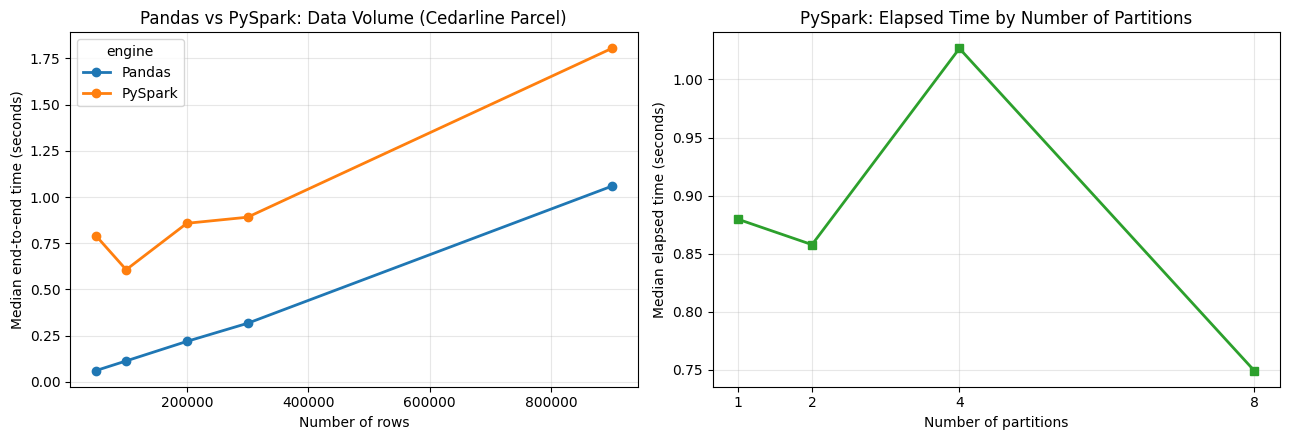

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Biểu đồ 1: Pandas vs PySpark theo kích thước dữ liệu
pivot_plot = summary_q4[["Pandas", "PySpark"]]
pivot_plot.plot(ax=axes[0], marker="o", linewidth=2)
axes[0].set_title("Pandas vs PySpark: Data Volume (Cedarline Parcel)")
axes[0].set_xlabel("Number of rows")
axes[0].set_ylabel("Median end-to-end time (seconds)")
axes[0].grid(alpha=0.3)

# Biểu đồ 2: Thời gian xử lý PySpark theo số Partition
part_df.plot(
    x="partitions",
    y="median_s",
    ax=axes[1],
    marker="s",
    color="tab:green",
    linewidth=2,
    legend=False,
)
axes[1].set_xticks([1, 2, 4, 8])
axes[1].set_title("PySpark: Elapsed Time by Number of Partitions")
axes[1].set_xlabel("Number of partitions")
axes[1].set_ylabel("Median elapsed time (seconds)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Khung kết luận thực nghiệm

(Điền số liệu thực tế từ bảng kết quả ở Câu 4, 6, 8 vào các ô [...])

Về quy mô dữ liệu (Volume): Khi tăng kích thước từ 50.000 lên 300.000 và 900.000 bản ghi, dung lượng tệp CSV tăng từ [...] MiB lên [...] MiB, kéo theo dung lượng RAM chiếm dụng của Pandas DataFrame (dù đã lọc chỉ lấy 5 cột) tăng tuyến tính từ [...] MiB lên [...] MiB. Thời gian thực thi của Pandas tăng rõ rệt từ [...] s lên [...] s.

Về khả năng mở rộng (Scalability): Ở quy mô nhỏ (50.000 dòng), PySpark mất [...] s so với [...] s của Pandas (Speedup = [...]), chậm hơn do phải gánh chi phí khởi tạo và điều phối cố định (overhead) lớn hơn khối lượng tính toán. Tuy nhiên, khi dữ liệu mở rộng lên 900.000 dòng, đường thời gian của PySpark tăng chậm hơn ([...] s so với [...] s của Pandas, Speedup = [...]), cho thấy lợi thế giữ nhịp ổn định khi dữ liệu phình to.

Về cơ chế đánh giá lười (Lazy evaluation): Phép thử ở Câu 6 chứng minh việc khai báo chuỗi biến đổi trên 300.000 dòng chỉ mất [...] s do Spark chỉ dựng kế hoạch xử lý logic, và chỉ thực sự đọc đĩa, lọc, shuffle (Exchange) khi gọi lệnh collect() ([...] s). Nhờ biết trước toàn bộ chuỗi lệnh, Spark tự động lược bỏ các cột thừa và tối ưu cộng gộp cục bộ trước khi trao đổi dữ liệu.

Về sự khác nhau giữa Spark local và Spark cluster: Toàn bộ thí nghiệm được chạy trên một máy ảo Colab ở chế độ local[*] ([2] vCPU, [12.7] GiB RAM), nơi các partition chỉ chia sẻ tài nguyên đa luồng trên cùng một máy và không mất chi phí truyền mạng qua lại giữa các máy chủ. Trong môi trường Spark cluster nhiều máy thực tế, hệ thống có thể mở rộng theo chiều ngang qua hàng chục nút độc lập để xử lý dữ liệu hàng trăm GB/TB vượt quá RAM một máy, nhưng đồng thời cũng phát sinh độ trễ truyền tải dữ liệu qua mạng (network shuffle) mà thí nghiệm đơn máy chưa phản ánh hết.